# 1. The store, its reward, and its exact model

This notebook sets up everything the later notebooks rely on:

1. the simulator (`code/retail_env.py`) and what one episode looks like;
2. the reward the project proposal used, and the loop it accidentally pays for;
3. the exact model of the same store (`code/mdp.py`), and checks that the model and the simulator agree.

Every number in the report comes from code in `code/`; the notebooks import it instead of re-defining it.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1.1 One episode in the simulator

The robot starts at the depot (0, 0) carrying two units. Two shelves hold up to three units each. Every step, each shelf that still has stock loses a unit with probability 0.12. The episode is cut after 200 steps; the store itself does not stop, so step 200 is a time limit and not a terminal state.

shelves: [(3, 0), (2, 2)] | depot: (0, 0)
observation [x, y, carried, stock1, stock2, since_visit1, since_visit2, time_of_day]: [0. 0. 2. 3. 3. 0. 0. 0.]
Markov state used by every agent and by the model: (0, 0, 2, (3, 3))


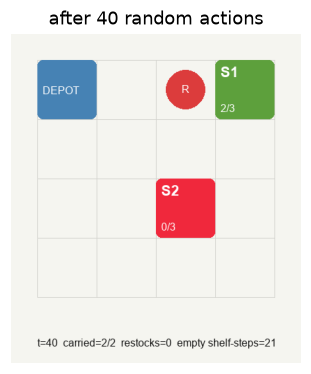

{'restocks': 0, 'proactive': 0, 'units_delivered': 0, 'empty_shelf_steps': 21, 'stockouts': 1, 'distance': 18, 'invalid': 11, 'objective': -169.79999999999998}


In [2]:
import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
from retail_env import RetailRestockEnv, ACTION_NAMES, COMPONENTS

env = RetailRestockEnv(seed=0, reward="objective", render_mode="rgb_array")
obs, _ = env.reset(seed=1)
print("shelves:", env.shelf_positions, "| depot:", env.depot_pos)
print("observation [x, y, carried, stock1, stock2, since_visit1, since_visit2, time_of_day]:", obs)
print("Markov state used by every agent and by the model:", env.state_key())

rng = np.random.default_rng(0)
for t in range(40):
    env.step(int(rng.integers(7)))
frame = env.render()
plt.figure(figsize=(3.4, 4)); plt.imshow(frame); plt.axis("off")
plt.title("after 40 random actions"); plt.show()
print(env.stats)

## 1.2 Reward components

`step()` reports every reward term separately in `info["components"]`, so any reward can be rebuilt from the same episode and every agent can be scored on the same quantity (`info["objective"]`) whatever it was trained on.

| preset | definition |
|---|---|
| `proposal` | $-8\,n_{empty} - 0.1\,moved - 0.2 - 1\,invalid + 10\,proactive + 5\,reactive + 2\,closer$ |
| `objective` | $-8\,n_{empty} - 0.1\,moved$ (lost availability and robot travel) |
| `pbrs` | objective $+\;\gamma\Phi(s') - \Phi(s)$, $\;\Phi = -2\cdot$ distance to the lowest-stock shelf |
| `pbrs_stock` | as `pbrs` with $\Phi$ also $+5\cdot$ units on the shelves |

In [3]:
env = RetailRestockEnv(seed=0, reward="proposal")
env.reset(seed=3)
_, r, _, _, info = env.step(3)          # move right, toward shelf S1 at (3, 0)
print("one step:", info["components"], "| proposal reward", round(r, 2), "| objective", info["objective"])

one step: {'n_empty': 0, 'moved': 1, 'step': 1, 'invalid': 0, 'restock_proactive': 0, 'restock_reactive': 0, 'closer': 1} | proposal reward 1.7 | objective -0.1


### The loop the proposal reward pays for

The `closer` bonus pays +2 for any step that reduces the distance to the lowest-stock shelf, and nothing is taken back for stepping away. With full shelves (no stockout penalty), compare walking back and forth with standing still:

In [4]:
def returns(actions, reward, gamma=0.95):
    env = RetailRestockEnv(seed=0, reward=reward, demand_prob=0.0)   # demand off: isolate the shaping term
    env.reset(seed=0)
    rs = [env.step(a)[1] for a in actions]
    return sum(rs), sum(gamma ** t * r for t, r in enumerate(rs))

loop, wait = [3, 2] * 50, [6, 6] * 50      # right, left, right, left ... versus standing still
print(f"{'reward':10s} {'loop (sum)':>11s} {'wait (sum)':>11s} | {'loop (disc.)':>13s} {'wait (disc.)':>13s} {'loop - wait (disc.)':>20s}")
for reward in ("proposal", "objective", "pbrs"):
    (l, ld), (w, wd) = returns(loop, reward), returns(wait, reward)
    print(f"{reward:10s} {l:11.1f} {w:11.1f} | {ld:13.2f} {wd:13.2f} {ld - wd:20.2f}")

reward      loop (sum)  wait (sum) |  loop (disc.)  wait (disc.)  loop - wait (disc.)
proposal          70.0       -20.0 |         14.43         -3.98                18.40
objective        -10.0         0.0 |         -1.99          0.00                -1.99
pbrs              15.0        30.0 |          3.98          5.96                -1.99


Under the proposal reward the loop earns $+1.7 - 0.3 = +1.4$ every two steps against $-0.4$ for waiting, so an agent can profit from pacing up and down. Under potential-based shaping the comparison that matters is the *discounted* one, because that is what the agent maximises and what the theorem of Ng et al. is about: the discounted shaped return equals the discounted objective return minus $\Phi(s_0)$ plus a term of order $\gamma^{T}$, so the loop-versus-wait difference under `pbrs` is the same as under `objective` (both show the loop's travel cost and nothing else).

The undiscounted sums under `pbrs` look odd (waiting earns +30): summed without discounting, the shaping terms leave a residual $-(1-\gamma)\sum_t \Phi(s_t)$, which is positive because $\Phi \le 0$. It does not change which policy is optimal, but it is a reason to report every agent on the objective rather than on the reward it trained with, as this project does.

Section IV of the report asks whether the optimal policy under the proposal reward actually exploits the loop; notebook 2 answers it exactly.

## 1.3 The exact model

The dynamics depend only on $(x, y, \text{carried}, \text{stock}_1, \text{stock}_2)$: $4\cdot4\cdot3\cdot4\cdot4 = 768$ states. Time since visit and time of day are in the observation but enter neither the transitions nor the objective, so this tuple is a Markov state. `StoreMDP` enumerates, for every state and action, the at most $2^2$ demand outcomes.

In [5]:
from mdp import StoreMDP
m = StoreMDP(layout_seed=0)
print(m.nS, "states x", m.nA, "actions x", m.nB, "demand branches; start state", m.states[m.start])
s = m.index[(3, 0, 2, (1, 3))]             # robot on S1, carrying 2, S1 has 1 unit
for b in range(m.nB):
    if m.P[s, 4, b] > 0:
        print("restock ->", m.states[m.NS[s, 4, b]], "p =", round(m.P[s, 4, b], 4),
              " n_empty =", int(m.C['n_empty'][s, 4, b]))

768 states x 7 actions x 4 demand branches; start state (0, 0, 2, (3, 3))
restock -> (3, 0, 0, (3, 3)) p = 0.7744  n_empty = 0
restock -> (3, 0, 0, (3, 2)) p = 0.1056  n_empty = 0
restock -> (3, 0, 0, (2, 3)) p = 0.1056  n_empty = 0
restock -> (3, 0, 0, (2, 2)) p = 0.0144  n_empty = 0


### Does the model match the simulator?

Two checks. First, put the simulator into random states, take random actions, and confirm every observed successor exists in the model with the same reward. Second, compare empirical successor frequencies with the model's probabilities. (The same checks run as unit tests in `tests/test_core.py`.)

In [6]:
def force(env, s):
    env.robot_pos = [s[0], s[1]]; env.carried = s[2]; env.stock = np.array(s[3], dtype=np.int32)

rng = np.random.default_rng(0)
worst = 0.0
for reward in ("proposal", "objective", "pbrs", "pbrs_stock"):
    env, R = RetailRestockEnv(seed=0, reward=reward), m.reward(reward)
    for k in range(2000):
        s, a = m.states[rng.integers(m.nS)], int(rng.integers(7))
        env.reset(seed=k); force(env, s)
        _, r, *_ = env.step(a)
        si, s2 = m.index[s], m.index[env.state_key()]
        b = [b for b in range(m.nB) if m.P[si, a, b] > 0 and m.NS[si, a, b] == s2]
        assert b, "successor missing from the model"
        worst = max(worst, abs(r - R[si, a, b[0]]))
print("8000 random transitions: every successor found; largest reward difference", worst)

s, a, n = (2, 2, 2, (2, 2)), 6, 20000
env = RetailRestockEnv(seed=0); counts = {}
for k in range(n):
    env.reset(seed=k); force(env, s); env.step(a)
    counts[env.state_key()] = counts.get(env.state_key(), 0) + 1
si = m.index[s]
for b in range(m.nB):
    s2 = m.states[m.NS[si, a, b]]
    print(f"{str(s2):24s} model {m.P[si, a, b]:.4f}   simulator {counts.get(s2, 0) / n:.4f}")

8000 random transitions: every successor found; largest reward difference

 5.773159728050814e-15
(2, 2, 2, (2, 2))        model 0.7744   simulator 0.7699
(2, 2, 2, (2, 1))        model 0.1056   simulator 0.1076
(2, 2, 2, (1, 2))        model 0.1056   simulator 0.1089
(2, 2, 2, (1, 1))        model 0.0144   simulator 0.0135


## 1.4 Exact evaluation of a policy

Because every agent in the study acts on the Markov state, any trained policy can be written as a 768-entry table and evaluated *exactly* by pushing the state distribution forward 200 steps: $d_{t+1} = d_t P_\pi$. Below, the uniform-random policy is evaluated exactly and by 300 simulated episodes.

In [7]:
from evaluation import simulate
uniform = np.full((m.nS, m.nA), 1 / m.nA)
exact = m.episode_metrics(uniform)
sim = simulate(lambda env: int(np.random.randint(7)), 0, n_episodes=300)
print(f"objective   exact {exact['objective']:8.1f}   simulated {sim['objective'].mean():8.1f} +/- {sim['objective'].std(ddof=1)/np.sqrt(300):.1f}")
print(f"service     exact {exact['service_level']:8.3f}   simulated {sim['service_level'].mean():8.3f}")
print(f"travel      exact {exact['distance']:8.1f}   simulated {sim['distance'].mean():8.1f}")

objective   exact  -2693.2   simulated  -2695.8 +/- 10.2


service     exact    0.161   simulated    0.160
travel      exact     85.2   simulated     85.5


## 1.5 The ten store layouts

Each training seed is a different store: the layout seed decides where the two shelves are. The optimal service level ranges widely, which is why results are reported as a normalised score (notebook 3). The figure is produced by `code/analyze.py`.

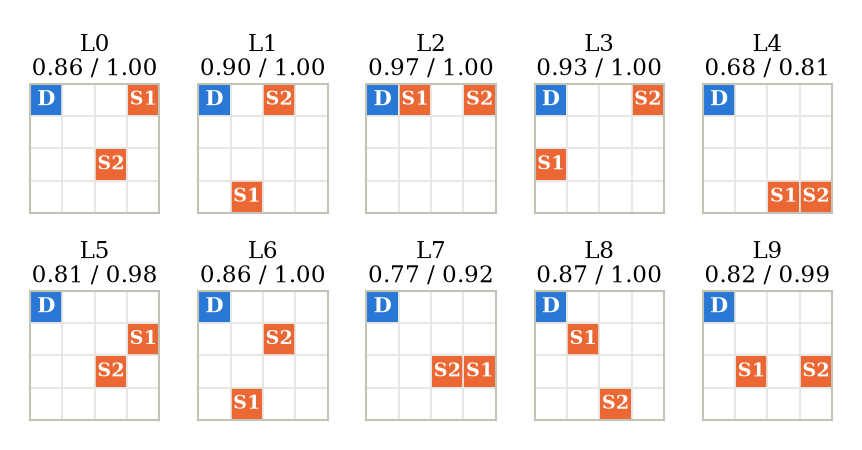

In [8]:
from IPython.display import Image
Image(filename=str(ROOT / "results/figures/layouts.png"), width=720)